<a href="https://colab.research.google.com/github/Meshi1520/Deep-learning/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dropout
from tensorflow.keras.utils import to_categorical



In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("oddrationale/mnist-in-csv")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mnist-in-csv' dataset.
Path to dataset files: /kaggle/input/mnist-in-csv


In [ ]:
df = pd.read_csv(r"/kaggle/input/mnist-in-csv/mnist_train.csv")
df_test = pd.read_csv(r"/kaggle/input/mnist-in-csv/mnist_test.csv")

In [ ]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
df.shape

(60000, 785)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to 28x28
dtypes: int64(785)
memory usage: 359.3 MB


In [ ]:
df.isnull().sum()

,0
label,0
1x1,0
1x2,0
1x3,0
1x4,0
...,...
28x24,0
28x25,0
28x26,0
28x27,0


In [ ]:
X_train = df.drop("label",axis = 1).values
y_train = df['label'].values
X_test = df_test.drop("label",axis = 1).values
y_test = df_test['label'].values

In [ ]:
#we have all the values between 0 and 255 so we do need to make it under 255
#to use networks vlaues between 0 and 1 are always preferred
X_train = X_train.astype('float32')/255.0
X_test = X_test.astype('float32')/255.0

In [ ]:
#now we reshape our data since our data is very large
X_train_img = X_train.reshape(-1,28,28)
X_test_img = X_test.reshape(-1,28,28)
 #rows = -1 and columns are 28 into 28
 #we converted all these into a flat list
 #first first column =-1 and second column = 28*28 matrix

In [ ]:
X_train_img

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [ ]:
#now we have one label and in it we have all those different images so we to do one hot encoding
y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

In [ ]:
# a perceptron has an input and an output layer we flatten the 28 * 28 layers into a single flattened layer so therre are 784 pictures for each layer
perceptron = Sequential([
    Flatten(input_shape=(28,28)),

    Dense(10,activation = 'softmax')

])
#we made a flatten layer and another layer of last layer

In [ ]:
perceptron.compile(optimizer='sgd',loss = 'categorical_crossentropy',metrics = ['accuracy'])

In [ ]:
history_percep = perceptron.fit(X_train_img,y_train_cat,epochs = 5,batch_size = 32,validation_data = (X_test_img,y_test_cat),verbose = True)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8121 - loss: 0.7796 - val_accuracy: 0.8791 - val_loss: 0.4841
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8802 - loss: 0.4582 - val_accuracy: 0.8936 - val_loss: 0.4018
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8908 - loss: 0.4046 - val_accuracy: 0.9024 - val_loss: 0.3677
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8970 - loss: 0.3777 - val_accuracy: 0.9053 - val_loss: 0.3492
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9006 - loss: 0.3607 - val_accuracy: 0.9091 - val_loss: 0.3362


In [ ]:
acc_percep = perceptron.evaluate(X_test_img,y_test_cat,verbose = 0)[1]

In [ ]:
acc_percep

0.9090999960899353

In [ ]:
ann = Sequential([
    Flatten(input_shape = (28,28)),
    Dense(128,activation = 'relu'),
    Dense(64,activation = 'relu'),
    Dense(10,activation = 'softmax')
])

In [ ]:
ann.compile(optimizer = 'adam',loss = 'categorical_crossentropy',metrics=['accuracy'])

In [ ]:
history_ann = ann.fit(X_train_img,y_train_cat,epochs = 5, batch_size = 32, validation_data = (X_test_img,y_test_cat),verbose = True)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.9297 - loss: 0.2400 - val_accuracy: 0.9635 - val_loss: 0.1207
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9682 - loss: 0.1047 - val_accuracy: 0.9728 - val_loss: 0.0876
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9777 - loss: 0.0731 - val_accuracy: 0.9739 - val_loss: 0.0855
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9831 - loss: 0.0542 - val_accuracy: 0.9767 - val_loss: 0.0781
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9860 - loss: 0.0428 - val_accuracy: 0.9788 - val_loss: 0.0779


In [ ]:
acc_ann = ann.evaluate((X_test_img),y_test_cat,verbose = 0)[1]

In [ ]:
acc_ann

0.9787999987602234

In [ ]:
X_train_cnn = X_train.reshape(-1,28,28,1)
X_test_cnn = X_test.reshape(-1,28,28,1)

In [ ]:
#now cnn we make a lot of layers here making a convolutional layer
cnn = Sequential([
    Conv2D(32,kernel_size = (3,3),activation = 'relu',input_shape = (28,28,1)),
    MaxPooling2D(pool_size = (2,2)),
    Conv2D(64,kernel_size = (3,3),activation = 'relu'),
    MaxPooling2D(pool_size = (2,2)),
    Flatten(), #a one dimensional array is made here
    Dense(128,activation = 'relu'),
    Dropout(0.5), # 50 percent neurons will decativate so that all neurons learn equally
    Dense(10,activation = 'softmax')



])

In [ ]:
cnn.compile(optimizer = 'adam',loss = 'categorical_crossentropy',metrics = ['accuracy'])

In [ ]:
cnn_history = cnn.fit(X_train_cnn, y_train_cat,epochs = 5,batch_size = 32, validation_data = (X_test_cnn,y_test_cat),verbose = 1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 60s 31ms/step - accuracy: 0.9380 - loss: 0.2022 - val_accuracy: 0.9844 - val_loss: 0.0467
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 80s 30ms/step - accuracy: 0.9776 - loss: 0.0771 - val_accuracy: 0.9881 - val_loss: 0.0379
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 30ms/step - accuracy: 0.9826 - loss: 0.0571 - val_accuracy: 0.9890 - val_loss: 0.0295
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 59s 32ms/step - accuracy: 0.9861 - loss: 0.0442 - val_accuracy: 0.9905 - val_loss: 0.0290
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 79s 30ms/step - accuracy: 0.9879 - loss: 0.0377 - val_accuracy: 0.9924 - val_loss: 0.0277


In [ ]:
acc_cnn =  cnn.evaluate(X_test_cnn,y_test_cat,verbose = 0)[1]

In [ ]:
acc_cnn

0.9923999905586243

### Perceptron Model Training History

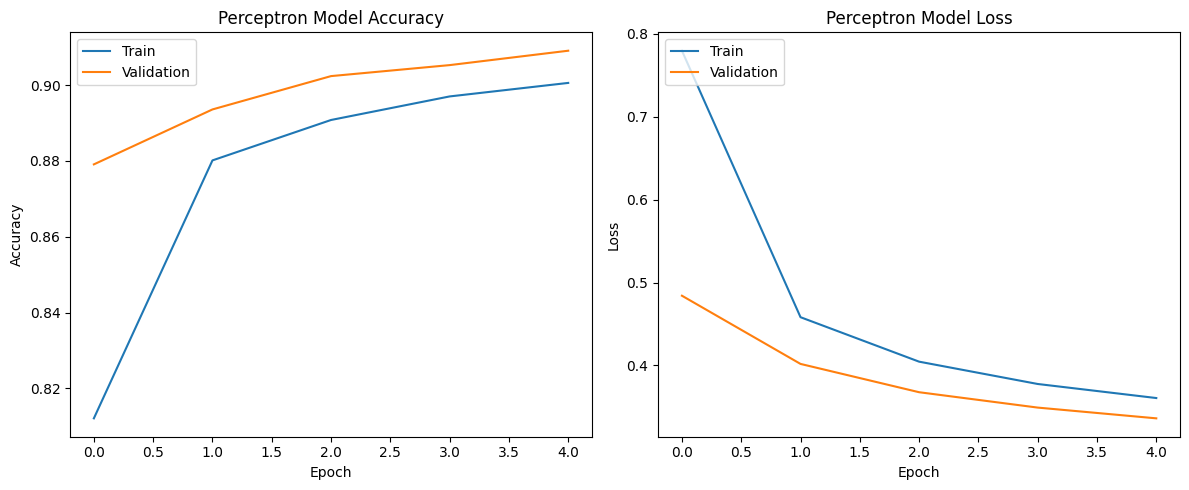

In [ ]:
plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(history_percep.history['accuracy'])
plt.plot(history_percep.history['val_accuracy'])
plt.title('Perceptron Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history_percep.history['loss'])
plt.plot(history_percep.history['val_loss'])
plt.title('Perceptron Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

### ANN Model Training History

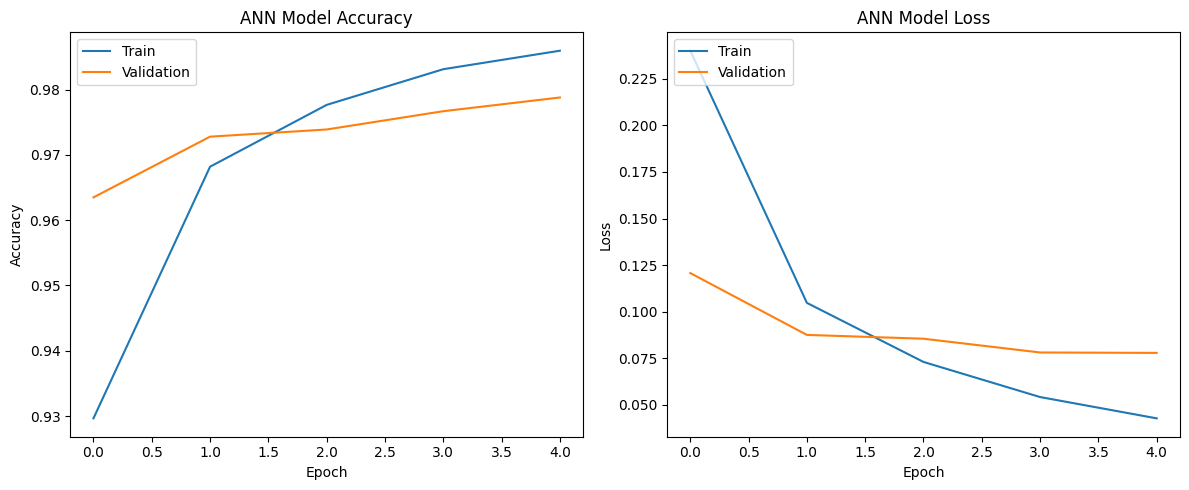

In [ ]:
plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(history_ann.history['accuracy'])
plt.plot(history_ann.history['val_accuracy'])
plt.title('ANN Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history_ann.history['loss'])
plt.plot(history_ann.history['val_loss'])
plt.title('ANN Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

### CNN Model Training History

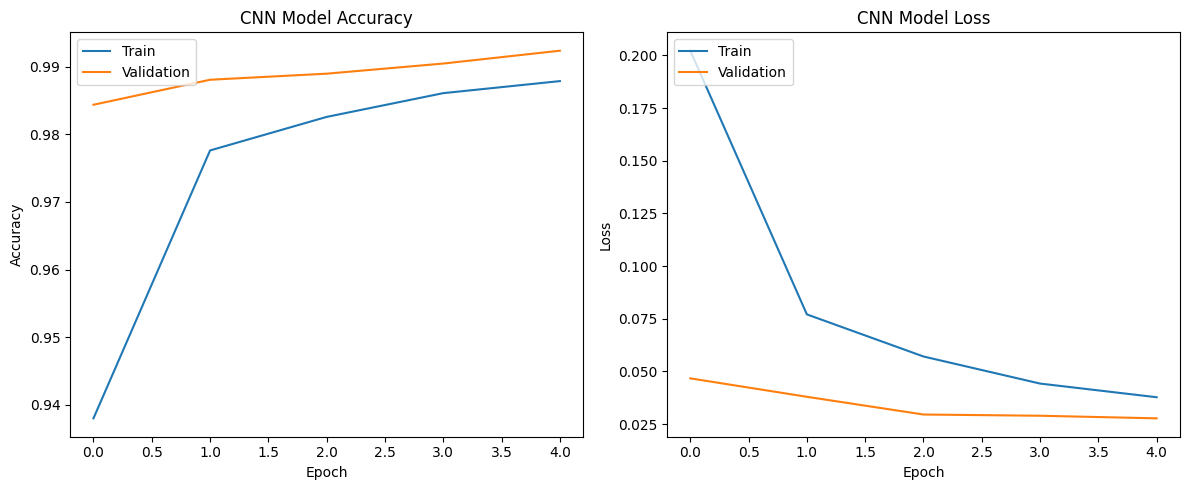

In [ ]:
plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['accuracy'])
plt.plot(cnn_history.history['val_accuracy'])
plt.title('CNN Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['loss'])
plt.plot(cnn_history.history['val_loss'])
plt.title('CNN Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()